# Reading ICON icosahedral grids with `pyramids-mesh`

**ICON** (ICOsahedral Nonhydrostatic) is the joint DWD/MPI weather and climate model. Its horizontal grid is built by recursively bisecting the edges of an icosahedron and projecting onto the sphere, yielding a **fully triangular** global mesh. Cell and vertex positions (`clon`/`clat`, `vlon`/`vlat`) are stored in **radians**, and connectivity (`vertex_of_cell`) is **1-based**.

This notebook reads a small **subset** of an R02B04 grid — the first 320 triangular cells and their 197 vertices, reindexed for the fixture — into a pyramids `UgridDataset`. Being triangular, ICON supports the full geometric toolbox including circumcenters.

## 1. Plotting backend and a `show()` helper

Every figure in this notebook is rendered through `cleopatra`/matplotlib. So the notebook executes identically in CI and interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot`. Agg draws into an off-screen buffer and never opens a GUI window; on its own it embeds nothing, so we add a tiny `show()` that grabs the current figure, saves it to a PNG buffer, and displays that buffer inline. Call `show()` after every plot.

In [1]:
import os
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0); display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd

## 3. Locate the example file

This notebook lives in `docs/examples/`, so `examples/data/` is two levels up. The ICON sample is `icon/icon_grid_R02B04_subset.nc`, a 320-cell triangular patch carved from the DWD/MPI R02B04 global grid.

Paths inside a notebook are always written **relative to the notebook itself**, and pyramids' `read_file` accepts a `pathlib.Path` directly — we pass the `Path`, never `str(path)`.

In [3]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "icon" / "icon_grid_R02B04_subset.nc"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/icon/icon_grid_R02B04_subset.nc'), True)

## 4. Read the mesh

`UgridDataset.read_file(path, driver="icon")` dispatches the file to the `icon` driver, which parses it and hands back a `UgridDataset` — the same pyramids type produced from a native UGRID NetCDF file. We name the driver explicitly here because several formats share the `.nc` suffix; `read_file` can auto-detect, but being explicit is unambiguous.

In [4]:
ds = UgridDataset.read_file(mesh_file, driver="icon")
type(ds).__name__

'UgridDataset'

From here nothing in the API remembers the data came from an ICON grid — it is a first-class pyramids object.

## 5. Explore the dataset

A `UgridDataset` exposes summary properties describing the whole mesh: `n_node` / `n_face` (size), `crs` / `epsg` (georeferencing, if the format recorded any), `bounds` (spatial extent), and `data_variable_names` (any attached fields).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": ds.bounds,
    "data_variable_names": ds.data_variable_names,
})

n_node                                                               197
n_face                                                               320
crs                                                                 None
epsg                                                                None
bounds                 (-1.1264011717823954e-15, 0.7308509730032275, ...
data_variable_names                                          [cell_area]
dtype: object

**320 triangular faces** on **197 nodes**. Unlike the other grids in this series, `data_variable_names` is **not empty** — the file ships a native `cell_area` field — and `crs`/`epsg` are still `None` (ICON records bare radian lon/lat, no CRS). The `bounds` are in radians.

## 6. Coordinates are in RADIANS

ICON stores longitude/latitude in **radians**. Because this is a *subset* (a small patch, not the whole globe) the longitude span is narrow, but the latitude reaches right up to the **north pole at π/2 ≈ 1.571** — the clinching evidence of radians rather than degrees.

In [6]:
nx, ny = np.asarray(ds.mesh.node_x), np.asarray(ds.mesh.node_y)
pd.Series({
    "node_x min/max": (float(nx.min()), float(nx.max())),
    "node_y min/max": (float(ny.min()), float(ny.max())),
    "two_pi": float(2*np.pi), "half_pi": float(np.pi/2),
})

node_x min/max    (-1.1264011717823954e-15, 1.256637061435918)
node_y min/max        (0.7308509730032275, 1.5707963267948948)
two_pi                                                6.283185
half_pi                                               1.570796
dtype: object

`node_y` tops out at **≈ 1.571 = π/2** (the pole) and `node_x` is a sub-`2π` arc — the values are radians. A degree grid would instead reach 90 and span up to 360. Convert with `np.degrees` before any CRS-aware step.

## 7. The underlying `Mesh2d` topology

`ds.mesh` is the `Mesh2d` holding the raw topology. The arrays you reach for most often are `node_x`/`node_y` (node coordinates), `face_node_connectivity.data` — the `(n_face, k)` table listing the node indices of each face — and `face_areas` (one value per face).

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
{
    "n_node": int(mesh.node_x.shape[0]),
    "connectivity_shape": conn.shape,
    "face_areas_shape": np.asarray(mesh.face_areas).shape,
    "face_centroids_shape": np.asarray(mesh.face_centroids).shape,
}

{'n_node': 197,
 'connectivity_shape': (320, 3),
 'face_areas_shape': (320,),
 'face_centroids_shape': (2, 320)}

The connectivity shape is **`(320, 3)`**: exactly **three** nodes per face — the defining signature of a triangular mesh, and what makes circumcenters well-defined later. `face_centroids` comes back as `(2, n_face)`.

## 8. The wireframe

The simplest visualization needs no data — just draw the cell edges. `plot_outline()` renders the mesh skeleton through cleopatra; it is the fastest sanity check that a file read in correctly.

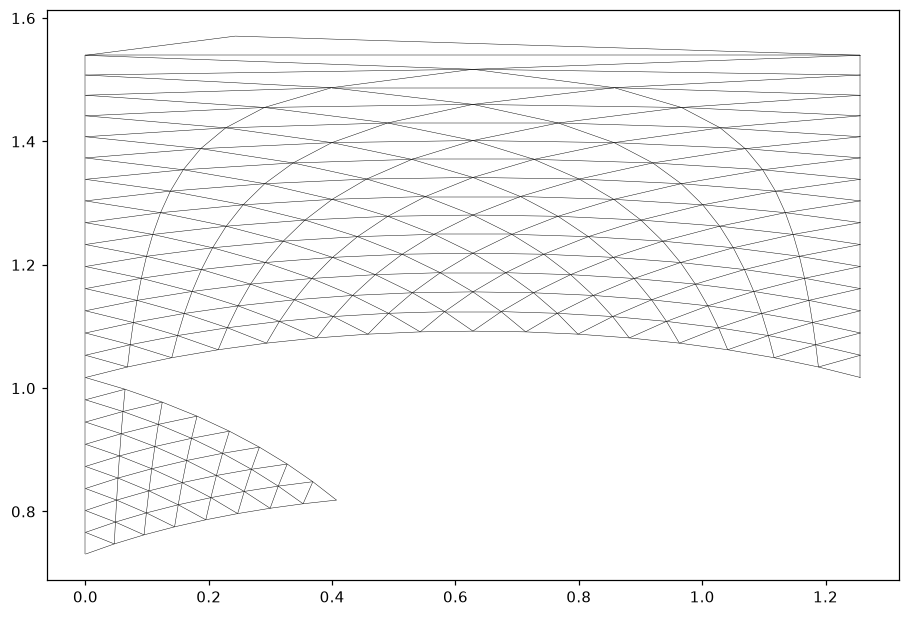

In [8]:
ds.plot_outline()
show()

The wireframe is a patch of ICON's icosahedral triangulation — near-equilateral triangles of very even size, the hallmark of a geodesic grid built by icosahedron bisection. The patch converges toward the pole at the top.

## 9. A data map: per-cell area

This file already carries a native `cell_area`, but to keep the series uniform we also compute the geometric area from the triangle coordinates and attach it as `face_area`. We compute each cell's area from the geometry and attach it as a face-located variable with `with_variable(...)`, which returns a **new** dataset (the original `ds` is left untouched). Colouring by it produces the generic pyramids data-map that any per-cell field (depth, velocity, …) would use.

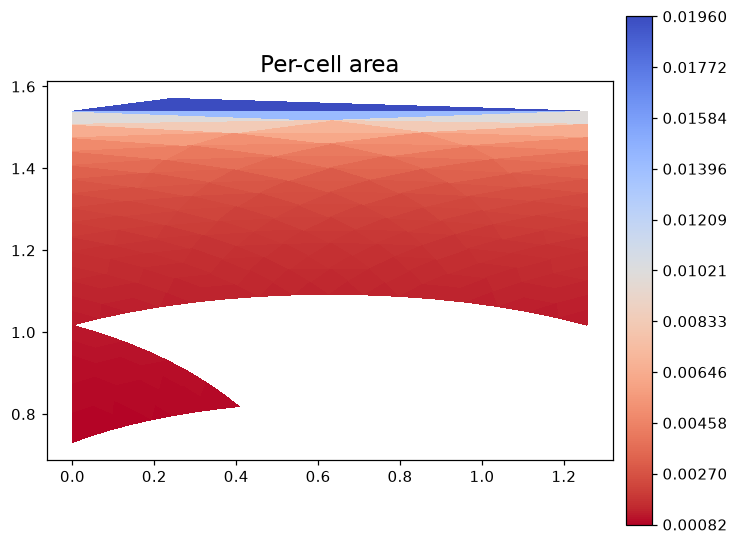

In [9]:
d2 = ds.with_variable("face_area", np.asarray(mesh.face_areas), location="face")
d2.plot("face_area", cmap="viridis", colorbar=True, title="Per-cell area")
show()

The triangles are shaded by area. The near-uniform colour reflects ICON's geodesic construction, which deliberately keeps cell sizes close to equal across the globe; the mild gradient is the lon/lat flattening toward the pole.

`summary()` reports per-variable statistics (count, min, max, mean, std) for every attached field.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,320,1.877728e+10,2.568455e+10,2.477042e+10,1.004190e+09
face_area,320,8.249722e-04,1.959623e-02,2.104748e-03,1.775881e-03


The `face_area` row (count = 320) quantifies the near-uniform sizing. Note the file's own native `cell_area` would summarise similarly — both describe the same triangles.

## 10. GIS operations, for free

Because the mesh is a pyramids object, the pyramids GIS layer applies directly — none of these methods live in `pyramids-mesh`. We tour a few.

### Faces as a `GeoDataFrame`

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or for spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0.24288 1.5708, 8.6551e-15 1.53961, ..."
1,"POLYGON ((8.6551e-15 1.53961, 2.39929e-15 1.50..."
2,"POLYGON ((0.62832 1.51701, 1.25664 1.53961, 8...."
3,"POLYGON ((1.25664 1.53961, 0.62832 1.51701, 1...."
4,"POLYGON ((2.39929e-15 1.50767, 5.96443e-16 1.4..."


One row per face, each carrying its cell polygon. Plotting the `GeoDataFrame` directly with geopandas draws every face as a filled polygon — a second, vector-native view of the same mesh.

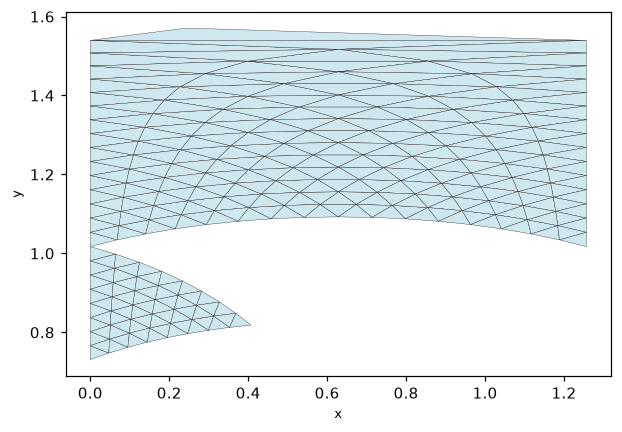

In [12]:
gdf.plot(edgecolor="black", linewidth=0.2, facecolor="#cfe8ef")
show()

Each row is a triangle polygon. As with the other global grids the CRS is unset; assign a geographic CRS before exporting.

### Bounding polygon

`bounding_polygon()` dissolves the triangles into the outline of the patch. Because this ICON subset is a small, non-seam-crossing region it dissolves cleanly (returning a shapely `MultiPolygon` when the patch is in more than one piece).

In [13]:
poly = ds.bounding_polygon()
{"type": type(poly).__name__, "bounds": ds.bounds}

{'type': 'MultiPolygon',
 'bounds': (-1.1264011717823954e-15,
  0.7308509730032275,
  1.256637061435918,
  1.5707963267948948)}

A shapely geometry describing the patch outline — the gateway to clipping, buffering and spatial joins. (A `MultiPolygon` would signal the patch is in several disconnected pieces, which the components section below confirms.)

### Circumcenters

`circumcenters()` returns an `(n_face, 2)` array of per-cell circumcenter coordinates — the points a finite-volume scheme places unknowns at. It is **defined only for triangular meshes**, and ICON is triangular, so it works here.

In [14]:
cc = np.asarray(ds.circumcenters())
cc.shape, cc[:3]

((320, 2),
 array([[ 0.62831853, -2.39214884],
        [ 0.31399123,  1.52363713],
        [ 0.62831853, 10.26348366]]))

`(n_face, 2)` — one `(x, y)` circumcenter per triangle. That these derived quantities are a single method call away is the whole point of turning the file into a pyramids object.

### Boundary edges and face adjacency

`exterior_edges()` returns the indices of the edges that lie on the mesh boundary (each interior edge is shared by two faces; a boundary edge by one). `sparse_adjacency()` returns the face–face adjacency as a SciPy sparse matrix — the graph a flow solver walks.

In [15]:
ee = np.asarray(ds.exterior_edges())
adj = ds.sparse_adjacency()
{
    "n_boundary_edges": int(ee.shape[0]),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}

{'n_boundary_edges': 72, 'adjacency_shape': (320, 320), 'adjacency_nnz': 888}

A non-zero boundary-edge count is expected for a finite patch (its outer rim), and the `(320, 320)` adjacency matrix encodes which triangles share an edge — the solver's neighbour graph.

### Connected components

`connected_components()` labels each face by which connected piece of the adjacency graph it belongs to. The number of distinct labels tells you whether the mesh is one contiguous surface or several disjoint pieces.

In [16]:
labels = np.asarray(ds.connected_components())
n_comp = int(np.unique(labels).size)
{"n_components": n_comp, "counts": np.bincount(labels).tolist()}

{'n_components': 2, 'counts': [256, 64]}

**Two** components: the 320-cell subset was carved as two disjoint patches of the global grid, so the adjacency graph splits in two. The `counts` show how many triangles fall in each piece — a nice demonstration that `connected_components` detects real disconnection, not just a formality.

### Cropping to a bounding box

`crop(bbox=(xmin, ymin, xmax, ymax))` returns a new `UgridDataset` holding only the faces inside the box — the mesh equivalent of a spatial window. (`subset_by_bounds(xmin, ymin, xmax, ymax)` does the same with positional arguments.) We crop to one quadrant of the extent and plot the result.

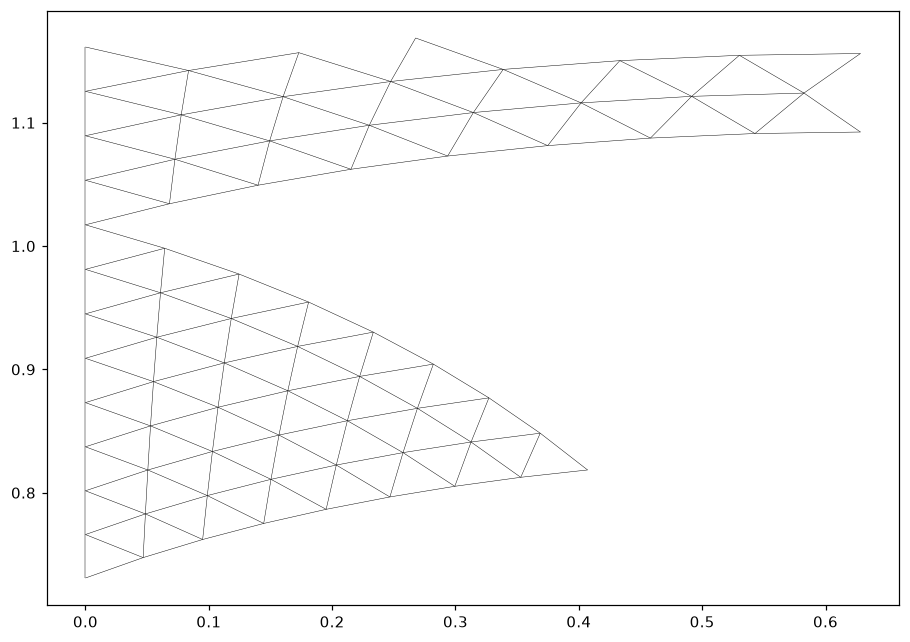

In [17]:
b = ds.bounds
bbox = (b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2)
cropped = ds.crop(bbox=bbox)
cropped.plot_outline()
show()

Cropping to one quadrant of the radian extent retains only the triangles inside the box — a still smaller slice of the icosahedral patch.

### Writing the mesh back out

`to_file(path, driver=...)` serialises the mesh through any **write-capable** driver. We round-trip to Stanford **PLY** (`driver="ply"`), which stores arbitrary polygon faces, into a temp file and read it back to confirm the topology survived.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "icon_roundtrip.ply"
ds.to_file(out, driver="ply")
back = UgridDataset.read_file(out, driver="ply")
{"wrote_bytes": out.stat().st_size, "n_face_back": back.n_face, "matches": back.n_face == ds.n_face}

{'wrote_bytes': 12999, 'n_face_back': 320, 'matches': True}

The face count survives the round-trip: the mesh we read from an ICON grid wrote cleanly to a different format and came back identical. PLY is used because this format's own driver is read-only — `to_file` dispatches to whichever driver advertises a write capability.

### Back to `xarray`

`to_xarray()` exposes the dataset as an `xarray.Dataset` of UGRID variables — the bridge to the wider scientific-Python stack (dask, NetCDF export, CF tooling).

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.dims)

('Dataset',
 ['mesh2d_scalar',
  'mesh2d_nNodes',
  'mesh2d_nFaces',
  'mesh2d_nMaxFaceNodes',
  'n_face'])

A standard `xarray.Dataset`: from here the mesh can be written to NetCDF, chunked with dask, or fed to any CF-aware tool.

## 11. What we *cannot* do here, and why

Two pyramids operations are unavailable on this mesh, and the reasons are instructive:

- **`to_crs(epsg)` — skipped.** This grid carries **no CRS** (`crs` is `None` above), so pyramids refuses to reproject: `to_crs` raises *"Cannot reproject: source CRS is unknown."* You would first assign the known CRS (these global grids are geographic lon/lat on a sphere) and only then reproject.
- **`rasterize_like(...)` / `regrid(...)` — out of scope here.** Burning the mesh onto a raster grid or remapping between meshes is a genuine pyramids capability, but it needs a target raster/mesh and a resampling choice to be meaningful — a topic for a dedicated regridding tutorial, not this format tour.

## Takeaway

- The `icon` driver reads an ICON icosahedral grid into a pyramids `UgridDataset`, handling the 1-based `vertex_of_cell` connectivity.
- ICON cells are **triangles** (`k = 3`) with coordinates in **radians** (latitude → π/2 at the pole); being triangular, **`circumcenters()` works**.
- The file ships a native `cell_area`; we also attached a geometric one for a uniform data map.
- `connected_components` found **2 disjoint patches** in this subset — a real structural fact, not an artifact — while `to_crs` is skipped (no CRS) with an explained reason.